# Custom Data Augmentation Pipeline: Visualization & Verification

## Overview
This notebook visualizes the custom data augmentation pipeline implemented for the semantic segmentation task.
We implemented a **native PyTorch/PIL augmentation pipeline** from scratch.
This notebook makes sure that geometric transformations (crops, flips, affine) are applied consistently to both the input image and the semantic segmentation label (mask).

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
from pathlib import Path
from PIL import Image

from augmentations import (
    JointCompose, JointToTensor, JointResize, JointRandomHorizontalFlip,
    JointRandomAffine, JointColorJitter, RandomBlur, RandomNoise,
    RandomCoarseDropout, OneOf, JointRandomScale, JointRandomCrop
)

data_dir = Path('')  # Path leading to the Dataset
img_dir = data_dir / "leftImg8bit" / "train"
label_dir = data_dir / "gtFine" / "train"

In [5]:
# 1. Search for and load image & label
city_folders = list(img_dir.glob("*"))

if not city_folders:
    print("WARNING: No folders found.")
else:
    first_city = city_folders[0]
    img_path = sorted(first_city.glob("*_leftImg8bit.png"))[0]
    label_name = img_path.name.replace("_leftImg8bit.png", "_gtFine_labelTrainIds.png")
    label_path = label_dir / first_city.name / label_name

    print(f"Loading image: {img_path}")

    # Load image -> PIL
    image_cv = cv2.imread(str(img_path))
    image_cv = cv2.cvtColor(image_cv, cv2.COLOR_BGR2RGB)
    image = Image.fromarray(image_cv)

    # Load label -> PIL
    mask_cv = cv2.imread(str(label_path), cv2.IMREAD_UNCHANGED)
    mask = Image.fromarray(mask_cv)

    # --- 2. Define augmentations ---

    # Definition of the full pipeline (as in your snippet, without ToTensor for visualization)
    full_pipeline_transforms = [
        JointRandomScale(scale_range=(0.5, 1.0)),
        JointRandomCrop(size=(512, 1024)),
        JointRandomHorizontalFlip(p=0.5),
        JointRandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.8, 1.2), p=1.0),
        OneOf([
            RandomNoise(intensity=50),
            RandomBlur(),
        ], p=0.3),
        OneOf([
            JointColorJitter(brightness=0.5, contrast=0.6, saturation=0.5, hue=0.2),
        ], p=0.5),
        RandomCoarseDropout(max_holes=10, max_height=64, max_width=64, p=1.0)
    ]

    augmentations_to_test = [
        # A. Baseline
        (
            "Original (Resize 512x1024 only)",
            JointCompose([JointResize(size=(512, 1024))])
        ),
        (
            "1. Scale & Crop",
            JointCompose([
                JointRandomScale(scale_range=(0.5, 1.0)),
                JointRandomCrop(size=(512, 1024))
            ])
        ),
        (
            "2. Horizontal Flip",
            JointCompose([
                JointResize(size=(512, 1024)),
                JointRandomHorizontalFlip(p=1.0)
            ])
        ),
        (
            "3. Affine (Rotation/Shift/Scale)",
            JointCompose([
                JointResize(size=(512, 1024)),
                JointRandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.8, 1.2), p=1.0)
            ])
        ),
        (
            "4. Noise / Blur (Distortions)",
            JointCompose([
                JointResize(size=(512, 1024)),
                OneOf([
                    RandomNoise(intensity=50),
                    RandomBlur(),
                ], p=1.0)
            ])
        ),
        (
            "5. Color Jitter (Color)",
            JointCompose([
                JointResize(size=(512, 1024)),
                JointColorJitter(brightness=0.5, contrast=0.6, saturation=0.5, hue=0.2)
            ])
        ),
        (
            "6. Coarse Dropout (Holes)",
            JointCompose([
                JointResize(size=(512, 1024)),
                RandomCoarseDropout(max_holes=10, max_height=64, max_width=64, p=1.0)
            ])
        ),

        # C. All together
        (
            "FULL PIPELINE (Training Config)",
            JointCompose(full_pipeline_transforms)
        )
    ]

Loading image: /Volumes/SanDisk/Ablage/cityscapes/leftImg8bit/train/jena/jena_000000_000019_leftImg8bit.png


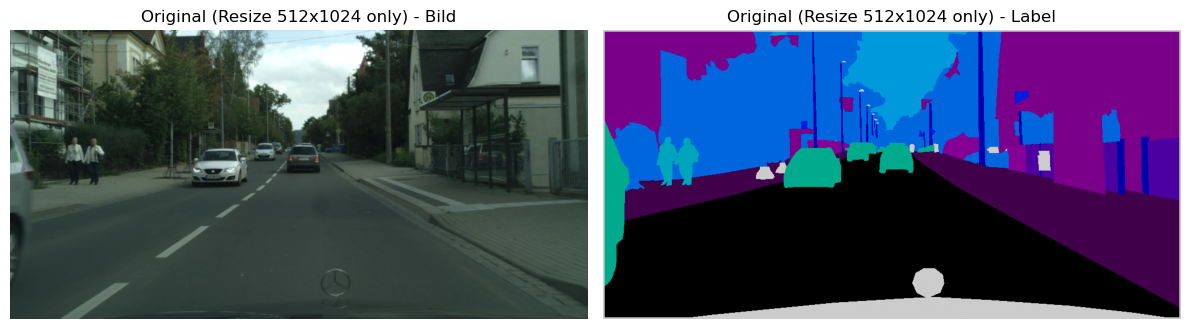

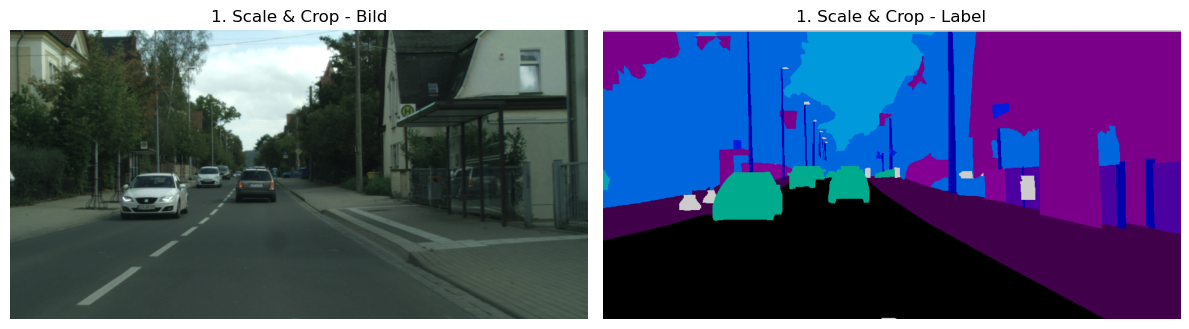

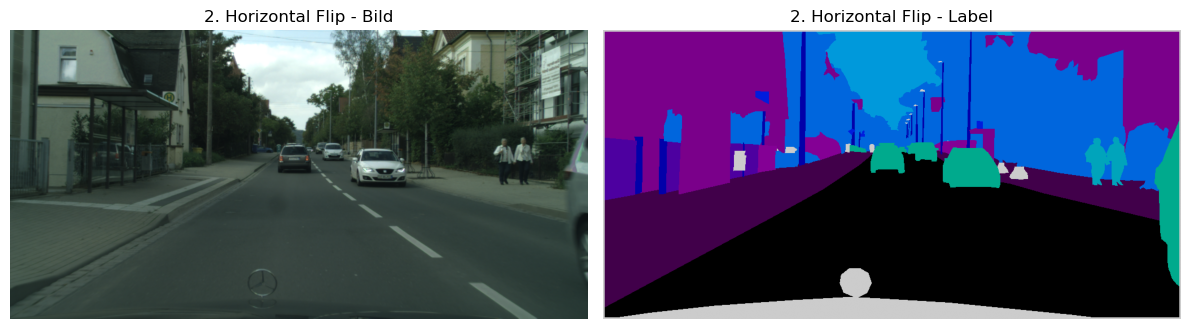

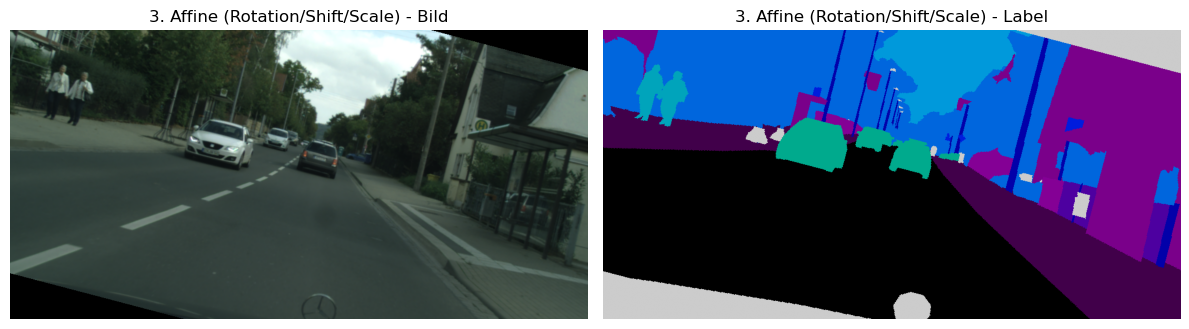

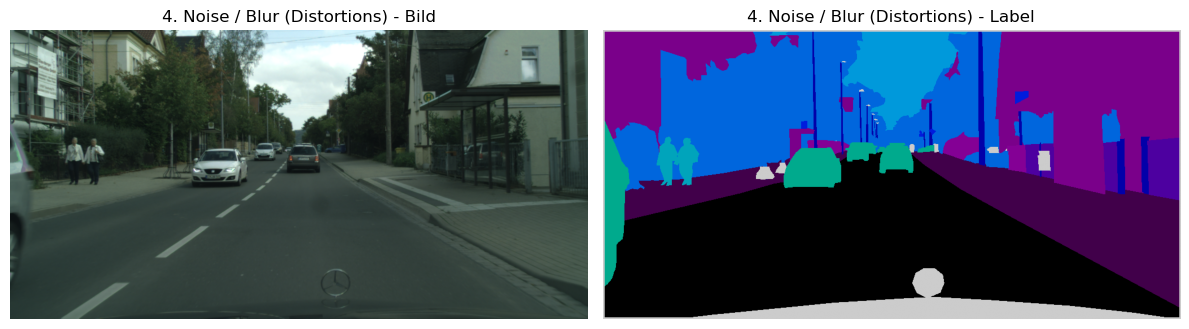

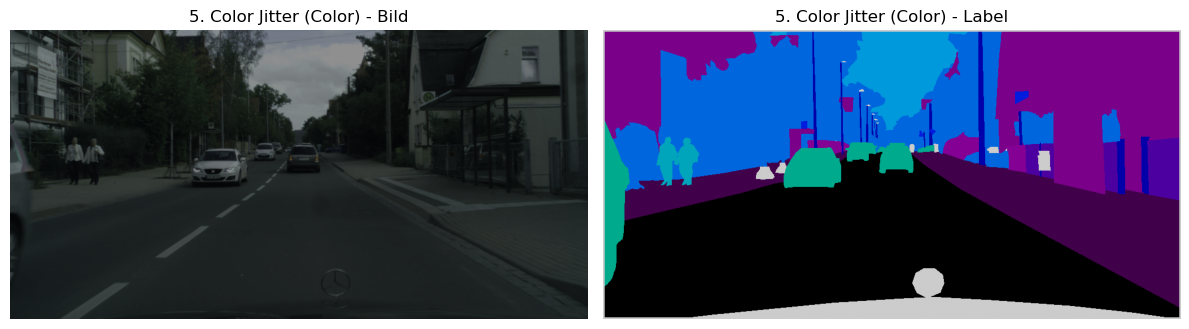

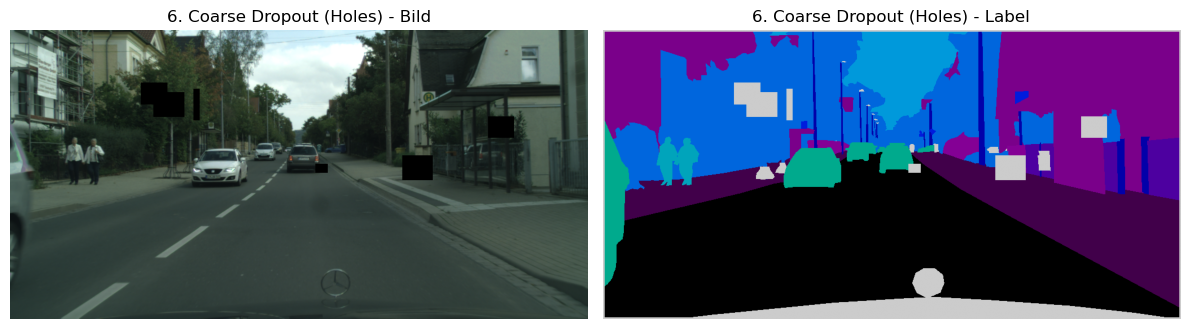

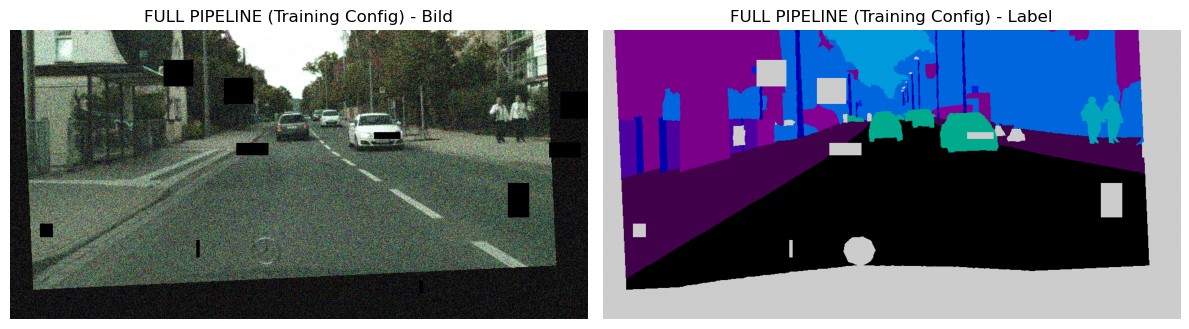

In [6]:
def visualize(image, mask, transforms_list):
    for title, transform in transforms_list:
        aug_img, aug_mask = transform(image.copy(), mask.copy())

        aug_img = np.array(aug_img)
        aug_mask = np.array(aug_mask)

        # Plotting
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))

        # Bild
        axes[0].imshow(aug_img)
        axes[0].set_title(f"{title} - Bild")
        axes[0].axis("off")

        axes[1].imshow(aug_mask, cmap='nipy_spectral', vmin=0, vmax=33)
        axes[1].set_title(f"{title} - Label")
        axes[1].axis("off")

        plt.tight_layout()
        plt.show()


# Ausführen
visualize(image, mask, augmentations_to_test)

### Observations
By comparing training runs against the baseline, we observed the following:

1.  **Effective Augmentations:**
    * **Geometric:** `RandomScale`, `RandomCrop`, and `HorizontalFlip` proved essential for preventing overfitting to spatial features.
    * **Photometric:** `ColorJitter` improved robustness against varying lighting conditions in the Cityscapes dataset.

2.  **Detrimental Augmentations (Rejected):**
    * **Synthetic Distortions:** Techniques like `RandomNoise`, `RandomBlur`, and `CoarseDropout` (Cutout) actually **decreased** the Validation mIoU. The model struggled to converge or learned artifacts that did not generalize well to the validation set.
    * **Affine Transformations:** Slight rotations and translations introduced too many "black borders" (ignore_index regions), effectively reducing the usable training data area without adding significant semantic value.

### Final Decision
Based on these empirical results, we **discarded** the detrimental augmentations. The final training pipeline consists exclusively of **Scale, Crop, Horizontal Flip, and Color Jitter**, as this combination yielded the highest robustness and mIoU score.

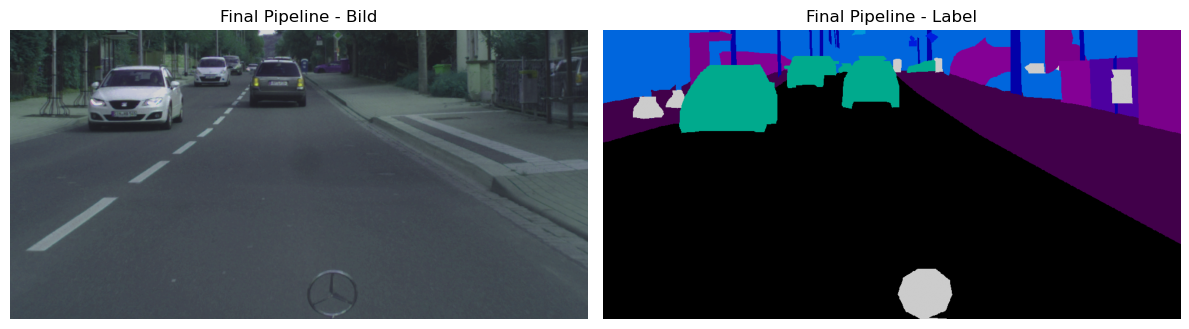

In [24]:
final_transform = JointCompose([
    JointRandomScale(scale_range=(0.5, 1.0)),
    JointRandomCrop(size=(512, 1024)),
    JointRandomHorizontalFlip(p=0.5),
    JointColorJitter(brightness=0.5, contrast=0.6, saturation=0.5, hue=0.2)
])

final_pipeline_samples =[
("Final Pipeline", final_transform)
]

visualize(image, mask, final_pipeline_samples)